# Derive fundamental physical parameters
Estimate fundamental parameters, including radius, bolometric luminosity, effective temperature, mass, surface gravity, and age, using observational data and atmospheric and evolutionary models.

In [1]:
import seda
import numpy as np
import matplotlib.pyplot as plt


    SEDA v0.8.10.dev48 package imported


## Radius ($R$)

**Two approaches are available to estimate the radius of an object:**

1. **Atmospheric models:** Compare self-consistent atmospheric models with observational data through forward modeling. The radius can be inferred from the scaling factor required to match the models to the observations, provided the distance to the object is known. Several [tutorials](https://seda--157.org.readthedocs.build/en/157/tutorials.html) demonstrate this approach for different combinations of observational data (spectra and/or photometry) and fitting techniques, as described in the **Chi-square minimization** and **Bayesian sampling** sections.

2. **Evolutionary models:** Interpolate a known bolometric luminosity and age within evolutionary models to estimate the radius, as implemented in the function [seda.phy_params.isochrone_params](https://seda--157.org.readthedocs.build/en/157/api.html#seda.phy_params.isochrone_params) and further described in the **Mass, Surface Gravity, Age, and Radius** section below.

## Bolometric Luminosity ($L_{\mathrm{bol}}$)

To estimate the bolometric luminosity of an object, a complete spectral energy distribution (SED) is constructed using the available observational data, complemented by a best-fitting model in regions lacking observations. The resulting *hybrid SED* is then integrated to derive the bolometric luminosity, provided the distance to the object is known. This procedure is implemented in the function [seda.phy_params.bol_lum](https://seda--157.org.readthedocs.build/en/157/api.html#seda.phy_params.bol_lum), as demonstrated in this [tutorial](https://seda--157.org.readthedocs.build/en/157/notebooks/tutorial_bolometric_luminosity.html).

## Effective Temperature ($T_{\mathrm{eff}}$)

**Two approaches are available to estimate the effective temperature of an object:**

1. **Stefan–Boltzmann law:** Calculate the effective temperature from the bolometric luminosity and radius, as implemented in the function [seda.phy_params.teff](https://seda--157.org.readthedocs.build/en/157/api.html#seda.phy_params.teff).

2. **Evolutionary models:** Interpolate a known bolometric luminosity and age (or radius) within evolutionary models to estimate the effective temperature, as implemented in the functions [seda.phy_params.isochrone_params](https://seda--157.org.readthedocs.build/en/157/api.html#seda.phy_params.isochrone_params) and [seda.phy_params.evol_params](https://seda--157.org.readthedocs.build/en/157/api.html#seda.phy_params.evol_params), respectively.

## Mass, Surface Gravity, Age, and Radius

**Two approaches are available to estimate additional fundamental parameters using evolutionary models:**

1. **Bolometric luminosity and radius:** Interpolate a known bolometric luminosity and radius within evolutionary models to estimate additional parameters, as implemented in the function [seda.phy_params.evol_params](https://seda--157.org.readthedocs.build/en/157/api.html#seda.phy_params.evol_params).

2. **Bolometric luminosity and age:** Interpolate a known bolometric luminosity and age within evolutionary models to estimate additional parameters, as implemented in the function [seda.phy_params.isochrone_params](https://seda--157.org.readthedocs.build/en/157/api.html#seda.phy_params.isochrone_params). This approach is particularly useful for objects belonging to young nearby moving groups with constrained ages or for companions whose host stars have known ages.

To visualize the parameter space covered by the evolutionary models, see this [tutorial](https://seda--157.org.readthedocs.build/en/157/notebooks/tutorial_evolutionary_models_examination.html).

**Available evolutionary models:**

In [2]:
seda.models.EvolutionaryModels().available_models

['ATMO2020',
 'BHAC2015',
 'SANDee',
 'Sonora_Bobcat',
 'Sonora_Diamondback',
 'Sonora_Flame_Skimmer',
 'Sonora_Red_Diamondback']

Evolutionary model tables for a selected model:

In [3]:
model = 'ATMO2020'
tables = seda.models.EvolutionaryModels(model).available_tables
tables

['ATMO_CEQ_mass.txt', 'ATMO_NEQ_strong_mass.txt', 'ATMO_NEQ_weak_mass.txt']

Selected parameters from an evolutionary model:

In [4]:
model = 'ATMO2020'
print(seda.models.EvolutionaryModels(model).ref) # reference
print(seda.models.EvolutionaryModels(model).ADS) # link to paper
print(seda.models.EvolutionaryModels(model).download) # link to download the models
print(seda.models.EvolutionaryModels(model).columns) # columns in each evolutionary table
print(seda.models.EvolutionaryModels(model).units) # units of each column
seda.models.EvolutionaryModels(model).params[tables[0]] # range of free parameters in a table

Phillips et al. (2020)
https://ui.adsabs.harvard.edu/abs/2020A%26A...637A..38P/abstract
https://noctis.erc-atmo.eu/fsdownload/zyU96xA6o/phillips2020
['mass', 'age', 'Teff', 'logL', 'radius', 'logg']
{'mass': 'M_jup', 'age': 'Gyr', 'Teff': 'K', 'logL': 'log10(L/Lsun)', 'radius': 'R_jup', 'logg': 'log(g[cm/s^2])'}


{'mass': [1.0475655146604772, 78.56741359953578],
 'age': [0.001, 10.0],
 'Teff': [206.71029843, 3156.67625353],
 'logL': [-7.74437436, -1.27027279],
 'radius': [0.7381504283556203, 7.740913051208527],
 'logg': [3.01108287, 5.51013179]}

### Infer parameters with `evol_params`

Given logarithmic bolometric luminosity and radius, interpolate the evolutionary grid to infer mass, age, surface gravity, and effective temperature:

In [5]:
# Example: solar-metallicity Bobcat
logL, elogL = -4.199, 0.048  # log10(L/Lsun)
R, eR = 1.018, 0.059         # R_jup

out = seda.phy_params.evol_params(
    logL=logL, elogL=elogL, R=R, eR=eR,
    model='Sonora_Bobcat', filename='nc+0.0_co1.0_mass',
)

25/10000 (0.2%) Monte Carlo samples fell outside the evolutionary grid and were excluded from the statistics.

Inferred fundamental parameters (Sonora Bobcat, nc+0.0_co1.0_mass):
   mass = 39.28 (-8.04, +10.05) M_jup
   age = 0.3669 (-0.1389, +0.2328) Gyr
   Teff = 1592 (-62.02, +64.68) K
   logg = 4.973 (-0.1495, +0.1487) log(g[cm/s^2])


### Infer parameters with `isochrone_params`

When radius is unknown but age is, use `isochrone_params` instead. The example below follows Zhang et al. (2021) GJ 570D (Table 6): the primary age is only constrained over **1.4–5.2 Gyr**, so we adopt a representative age of 3.3 Gyr with `eage = 1.9 Gyr` to span that range:

In [6]:
# Zhang et al. (2021) quote log10(L/L_sun); pass that directly to isochrone_params
logL = -5.54              # log10(L/L_sun)
elogL = 0.03              # uncertainty on log10(L/L_sun)

age_gyr = 3.3   # mid-point of the 1.4–5.2 Gyr primary age range
eage_gyr = 1.9  # half-width (~1.4 to 5.2 Gyr)

iso = seda.phy_params.isochrone_params(
    logL=logL, elogL=elogL,
    age=age_gyr, eage=eage_gyr,
    model='Sonora_Bobcat', filename='nc+0.0_co1.0_mass',
)

405/10000 (4.0%) Monte Carlo samples fell outside the evolutionary grid and were excluded from the statistics.

Inferred fundamental parameters (Sonora Bobcat, nc+0.0_co1.0_mass):
   mass = 38.32 (-10.7, +8.495) M_jup
   Teff = 796.4 (-34.12, +26.61) K
   logg = 5.102 (-0.2102, +0.1295) log(g[cm/s^2])
   radius = 0.8654 (-0.04279, +0.07038) R_jup


Visualize the same grid in **age–luminosity** space. `isochrone_params` takes `age` in Gyr and `logL` as log10(L/L_sun); the plot below shows linear Lbol on a logarithmic axis. The error bar shows the GJ 570D constraints from above:

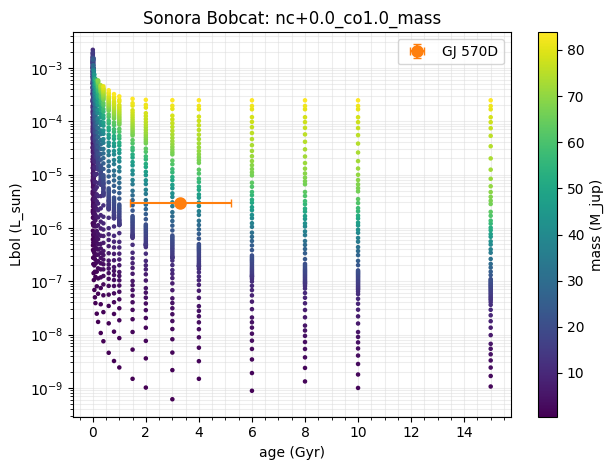

In [7]:
Lbol = 10.0 ** logL
eLbol = Lbol * np.log(10) * elogL

fig, ax = seda.plots.plot_evolutionary_coverage(
    model='Sonora_Bobcat',
    filename='nc+0.0_co1.0_mass',
    xparam='age',
    yparam='Lbol',
    zparam='mass',
    xlog=False,
    ylog=True,
)

ax.errorbar(
    age_gyr, Lbol, xerr=eage_gyr, yerr=eLbol,
    fmt='o', color='C1', ms=8, capsize=3, zorder=5, label='GJ 570D',
)
ax.legend(loc='upper right')

plt.show()